# Euler Deconvolution: Depth to Magnetic Basement beneath the Viburnum Trend, SE Missouri

| | |
|---|---|
| **Module** | M5 — Forward and Inverse Modeling (depth-to-source methods) |
| **Builds on** | M3 (dipole fields, total-field anomaly), M4 (homogeneous functions), M6 (wavenumber-domain derivatives) |
| **Textbook** | Blakely (1995), Ch. 10 |
| **Data** | USGS Earth MRI airborne magnetic survey, southeast Missouri, 2018–2019 (McCafferty & Johnson, 2019) |
| **Python** | `numpy`, `scipy`, `pandas`, `matplotlib` |

---

This demo estimates **where, and how deep, magnetic sources are** directly from
gridded magnetic data. It does not build a forward model. The tool is **Euler
deconvolution** (Thompson, 1982; Reid et al., 1990), the most widely used
automatic depth-to-source method in mineral exploration, regional mapping, and
unexploded-ordnance (UXO) detection.

**Roadmap**

1. **Background:** why potential fields obey Euler's homogeneity equation, and how
   that becomes a linear least-squares problem for the source position.
2. **Part 1 — Synthetic test:** a buried dipole with a known answer. We check the
   derivatives and show the trade-off between structural index (SI) and depth.
3. **Part 2 — Real data:** flight-line data from the USGS Earth MRI survey over the
   Viburnum Trend on the western flank of the St. Francois Mountains, gridded and
   differentiated.
4. **Part 3 — Moving-window Euler deconvolution** (Reid et al., 1990) for several SIs.
5. **Part 4 — Targeted Euler**, which mimics the Seequent UX-Detect
   *Calculate depths and weights (Euler)* workflow.
6. **Part 5 — Visualizing sources by depth**, plus discussion and exercises.

Everything runs with the standard scientific Python stack, and every algorithm is
written out explicitly so you can read and modify it. For a short companion
tutorial with a similar Python implementation, see Uieda et al. (2014).

## Background: the physics and mathematics of Euler deconvolution

### 1. Homogeneous functions and Euler's theorem

A function $f(\mathbf{r})$ is **homogeneous of degree $n$** if scaling all of its
coordinates by a factor $t$ scales the function by $t^n$:

$$
f(t\,\mathbf{r}) = t^{\,n} f(\mathbf{r}) .
$$

Differentiate both sides with respect to $t$ and then set $t = 1$. The chain rule
gives **Euler's homogeneity relation** (you met this in M4 when discussing solid
spherical harmonics):

$$
\mathbf{r}\cdot\nabla f = x\frac{\partial f}{\partial x} + y\frac{\partial f}{\partial y} + z\frac{\partial f}{\partial z} = n\,f .
$$

Nothing here is specific to geophysics. The geophysical content enters through
the observation that **the fields of simple sources are homogeneous functions of
the vector from the source to the observer**, $\mathbf{r}-\mathbf{r}_0$.

### 2. Potential fields of simple sources are homogeneous

| Source | Field | Degree of homogeneity in $\mathbf{r}-\mathbf{r}_0$ |
|---|---|---|
| Point mass | $U \propto 1/\lvert\mathbf{r}-\mathbf{r}_0\rvert$ | $-1$ |
| Point mass | $g_z \propto (z-z_0)/\lvert\mathbf{r}-\mathbf{r}_0\rvert^3$ | $-2$ |
| Point dipole | $V \propto \mathbf{m}\cdot(\mathbf{r}-\mathbf{r}_0)/\lvert\mathbf{r}-\mathbf{r}_0\rvert^3$ | $-2$ |
| Point dipole | $\mathbf{B} = \dfrac{\mu_0}{4\pi}\dfrac{3(\mathbf{m}\cdot\hat{\mathbf{u}})\hat{\mathbf{u}} - \mathbf{m}}{\lvert\mathbf{r}-\mathbf{r}_0\rvert^3}$ | $-3$ |

Because the total-field anomaly is (to excellent approximation, M3) the projection
of the anomalous field onto the ambient field direction $\hat{\mathbf{F}}$,

$$
\Delta T(\mathbf{r}) \approx \hat{\mathbf{F}}\cdot \Delta\mathbf{B}(\mathbf{r}),
$$

and $\hat{\mathbf{F}}$ is a constant vector over a survey, $\Delta T$ inherits the
homogeneity of $\Delta\mathbf{B}$. For a dipole, $\Delta T$ is homogeneous of degree
$-3$ in $\mathbf{r}-\mathbf{r}_0$ **for any direction of magnetization and any
inducing-field direction.** That is a big practical advantage: Euler deconvolution
does not need reduction to the pole, and remanence does not bias the location.

We write the degree as $-N$ and call $N$ the **structural index (SI)**. It is the
rate at which the field falls off with distance from the source.

### 3. Euler's equation for potential-field data

Apply Euler's relation to $\Delta T(\mathbf{r}-\mathbf{r}_0)$. Also allow a constant
regional background $B$ that is not part of the homogeneous source field. The
result is the equation of Thompson (1982) and Reid et al. (1990):

$$
\boxed{(x-x_0)\frac{\partial T}{\partial x} + (y-y_0)\frac{\partial T}{\partial y} + (z-z_0)\frac{\partial T}{\partial z} = N\,(B - T)}
$$

Here $(x, y, z)$ is the observation point and $(x_0, y_0, z_0)$ is the source
position. We use $x$ = east, $y$ = north, and $z$ **positive down** (Blakely's
convention). $T$ is the observed total-field anomaly and $B$ is the background
level.

Every observation point that "sees" the same simple source satisfies this
equation with the same $(x_0, y_0, z_0, B)$. Rearranged so the four unknowns
are on the left:

$$
x_0\,T_x + y_0\,T_y + z_0\,T_z + N B \;=\; x\,T_x + y\,T_y + z\,T_z + N\,T .
$$

For the $M$ grid points inside a data window, this is an overdetermined linear
system $\mathbf{A}\mathbf{p} = \mathbf{b}$:

$$
\underbrace{\begin{bmatrix}
T_{x,1} & T_{y,1} & T_{z,1} & N\\
\vdots & \vdots & \vdots & \vdots\\
T_{x,M} & T_{y,M} & T_{z,M} & N
\end{bmatrix}}_{\mathbf{A}}
\underbrace{\begin{bmatrix} x_0\\ y_0\\ z_0\\ B\end{bmatrix}}_{\mathbf{p}}
=
\underbrace{\begin{bmatrix}
x_1T_{x,1} + y_1T_{y,1} + z_1T_{z,1} + N T_1\\
\vdots\\
x_MT_{x,M} + y_MT_{y,M} + z_MT_{z,M} + N T_M
\end{bmatrix}}_{\mathbf{b}} .
$$

The weighted least-squares solution (weights $\mathbf{W}$, M5) and its covariance are

$$
\hat{\mathbf{p}} = (\mathbf{A}^{\mathsf T}\mathbf{W}\mathbf{A})^{-1}\mathbf{A}^{\mathsf T}\mathbf{W}\mathbf{b},
\qquad
\operatorname{Cov}(\hat{\mathbf{p}}) \approx \hat\sigma^2 (\mathbf{A}^{\mathsf T}\mathbf{W}\mathbf{A})^{-1},
\qquad
\hat\sigma^2 = \frac{\lVert \mathbf{W}^{1/2}(\mathbf{b}-\mathbf{A}\hat{\mathbf{p}})\rVert^2}{M-4}.
$$

The standard error $\sigma_{z_0}$, expressed as a percentage of the depth below the
sensor, is the usual **acceptance criterion**: Reid et al. (1990) and most software
reject solutions whose relative depth uncertainty exceeds a tolerance of roughly
10–20 %. Seequent's UX-Detect Euler tool reports this quantity as `Depth_Err` (%).

> **Note.** The data vector $\mathbf{b}$ contains the gradients, so $\mathbf{A}$ and
> $\mathbf{b}$ have correlated errors. Ordinary least squares is therefore slightly
> biased (an errors-in-variables problem). In practice this is minor compared with
> the effects of interfering sources and a wrong SI.

### 4. The structural index

Typical magnetic SI values (Reid et al., 1990; Reid & Thurston, 2014). For gravity,
subtract 1.

| Magnetic source geometry | Field falls off as | SI ($N$) |
|---|---|---|
| Point dipole, sphere, compact body (e.g., a UXO item, a pod-like ore body) | $r^{-3}$ | 3 |
| Line of dipoles: horizontal or vertical cylinder, pipe, pipe-like ore shoot | $r^{-2}$ | 2 |
| Thin dike or sill edge, thin sheet | $r^{-1}$ | 1 |
| Contact / thick step of large depth extent | ~$\log r$ | 0 (with caveats) |

Two points matter in practice:

1. **The SI and depth trade off.** Only the ratio between the field and its
   gradients is measured, so a source at depth $h$ assumed to have SI $N$ produces
   an estimated depth that scales approximately like $N$. **Too small an SI makes
   sources look too shallow; too large an SI makes them look too deep.** The
   synthetic test in Part 1 demonstrates this.
2. **Real geology is not homogeneous.** A finite body behaves like a dipole (SI 3)
   far away and like a contact (SI ≈ 0) close up. Non-integer SIs (2.5, 2.7, 0.5)
   appear in software tables, including Seequent's UXO table, as empirical
   compromises (Reid & Thurston, 2014).

### 5. Derivatives

Euler's equation needs all three gradient components:

* $\partial T/\partial x$ and $\partial T/\partial y$: computed in the space domain by
  central differences on the grid. Modern surveys sometimes measure these
  directly; this one has wing-tip gradiometers.
* $\partial T/\partial z$: computed in the **wavenumber domain** (M6). Because $T$ is
  harmonic above the sources, $\widetilde{T}(\mathbf{k}, z) = \widetilde{T}(\mathbf{k}, 0)\,e^{|\mathbf{k}|z}$
  with $z$ positive down, so

$$
\mathcal{F}\!\left[\frac{\partial T}{\partial z}\right] = |\mathbf{k}|\,\mathcal{F}[T].
$$

  This filter amplifies high wavenumbers like downward continuation does (M6.5),
  so noise and gridding artifacts are boosted. A small upward continuation before
  differentiating is a common stabilizer.

### 6. Practical algorithm (Reid et al., 1990)

1. Grid the line data onto a regular mesh.
2. Compute $T_x, T_y, T_z$.
3. Slide a square window of $w\times w$ cells across the grid. In each window, solve the
   $4\times 4$ least-squares problem for a *chosen* SI.
4. Reject poor solutions: large $\sigma_{z_0}/z_0$, solutions above the sensor, solutions
   far outside their window, and solutions much deeper than the window can resolve.
5. Plot the surviving solutions. Good solutions **cluster** at true sources;
   isolated solutions are usually spurious.

A **targeted** variant is used in UXO work (Seequent UX-Detect, *Calculate depths
and weights, Euler*; Seequent, 2025). First pick discrete anomaly peaks, usually maxima of the
analytic signal. Then centre a window on each target, weight each point inversely
by its distance from the window centre, and solve once per target. The tool
reports position, apparent depth, background field, and `Depth_Err` (%). It
converts depth below the sensor to depth below ground by subtracting the
instrument height. We reproduce this workflow in Part 4.

---
## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource, Normalize, LogNorm
import matplotlib.patheffects as pe
from numpy.lib.stride_tricks import sliding_window_view
from pathlib import Path
from scipy.interpolate import griddata
from scipy.ndimage import maximum_filter
from scipy.spatial import cKDTree

plt.rcParams.update({'figure.dpi': 90, 'axes.grid': False, 'font.size': 10,
                     'axes.titlesize': 11, 'image.origin': 'lower'})

DATA_DIR = Path('data')
if not DATA_DIR.exists():                      # allow running from the repo root too
    DATA_DIR = Path('demos') / 'data'
DATA_FILE = DATA_DIR / 'semo_viburnum_mag.csv.gz'
print('Data file:', DATA_FILE, '| exists:', DATA_FILE.exists())

Data file: data/semo_viburnum_mag.csv.gz | exists: True


---
## Part 1 — A synthetic test with a known answer

Before trusting Euler deconvolution on real data, we check it on a source whose
position we know. We use a point dipole (SI = 3) magnetized **by induction in the
present-day field over SE Missouri** ($I \approx 65.8^\circ$, $D \approx -0.8^\circ$,
from the IGRF values carried in the survey database). It sits 1500 m below sea
level, and the "survey" is flown at 300 m above sea level.

Coordinate convention throughout: $x$ = east, $y$ = north, $z$ = **down**, in metres.
An aircraft altitude of 300 m above sea level is therefore $z = -300$ m.

In [2]:
MU0 = 4e-7 * np.pi

def unit_vector(inc_deg, dec_deg):
    """Unit vector (east, north, down) for inclination/declination in degrees."""
    I, D = np.radians(inc_deg), np.radians(dec_deg)
    return np.array([np.cos(I) * np.sin(D), np.cos(I) * np.cos(D), np.sin(I)])

def dipole_tmi(x, y, z, x0, y0, z0, moment, inc, dec, f_inc, f_dec):
    """Total-field anomaly (nT) of a point dipole (moment in A m^2).
    The magnetization direction (inc, dec) and the ambient-field direction (f_inc, f_dec)
    can differ, e.g. to model remanence."""
    m = moment * unit_vector(inc, dec)
    rx, ry, rz = x - x0, y - y0, z - z0
    r = np.sqrt(rx**2 + ry**2 + rz**2)
    mdotr = m[0] * rx + m[1] * ry + m[2] * rz
    c = MU0 / (4 * np.pi) * 1e9                       # T -> nT
    B = [c * (3 * mdotr * ri / r**5 - mi / r**3) for ri, mi in zip((rx, ry, rz), m)]
    F = unit_vector(f_inc, f_dec)
    return F[0] * B[0] + F[1] * B[1] + F[2] * B[2]

# Present-day field over the survey area (from the IGRF_INC / IGRF_DEC channels)
F_INC, F_DEC = 65.8, -0.8

dx_s = 50.0
xs = np.arange(-10_000, 10_000 + dx_s, dx_s)
Xs, Ys = np.meshgrid(xs, xs)
Zs = np.full_like(Xs, -300.0)                         # flying 300 m above sea level
src = dict(x0=500.0, y0=-800.0, z0=1500.0, moment=5e9,
           inc=F_INC, dec=F_DEC, f_inc=F_INC, f_dec=F_DEC)
T_syn = dipole_tmi(Xs, Ys, Zs, **src)
print(f'Synthetic anomaly range: {T_syn.min():.1f} to {T_syn.max():.1f} nT')

Synthetic anomaly range: -18.9 to 149.7 nT


### Computing the three gradient components

The horizontal derivatives are central differences. The vertical derivative uses
the wavenumber-domain filter $|\mathbf{k}|$ from M6. To reduce wrap-around (edge)
artifacts we first pad the grid by reflection. We then compare the FFT result
with an exact finite difference of the forward model.

Max |FFT dT/dz - exact| relative to peak: 0.19 %


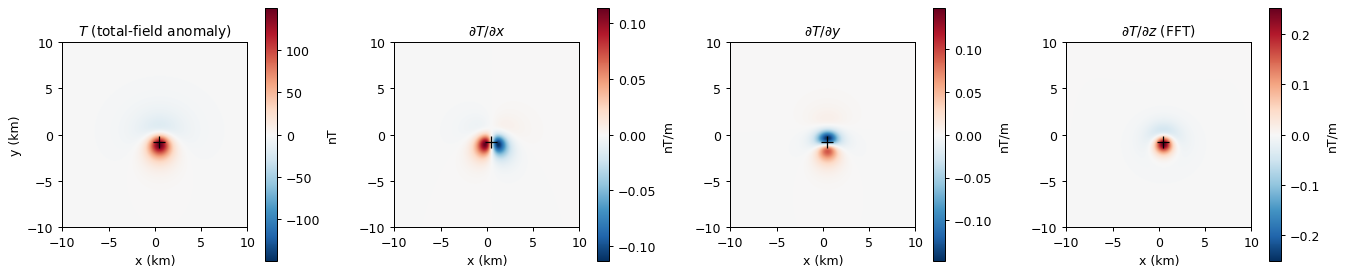

In [3]:
def vertical_derivative(T, dx, dy, up=0.0):
    """dT/dz (z positive down) by FFT with reflective padding.
    `up` > 0 additionally upward-continues by that many metres (a stabilizer)."""
    ny, nx = T.shape
    py, px = ny // 2, nx // 2
    Tp = np.pad(T - np.nanmean(T), ((py, py), (px, px)), mode='reflect')
    kx = 2 * np.pi * np.fft.fftfreq(Tp.shape[1], d=dx)
    ky = 2 * np.pi * np.fft.fftfreq(Tp.shape[0], d=dy)
    K = np.hypot(*np.meshgrid(kx, ky))
    filt = K * np.exp(-K * up)
    return np.real(np.fft.ifft2(np.fft.fft2(Tp) * filt))[py:py + ny, px:px + nx]

def upward_continue(T, dx, dy, up):
    """Upward continuation by `up` metres (same padding scheme)."""
    ny, nx = T.shape
    py, px = ny // 2, nx // 2
    mu = np.nanmean(T)
    Tp = np.pad(T - mu, ((py, py), (px, px)), mode='reflect')
    kx = 2 * np.pi * np.fft.fftfreq(Tp.shape[1], d=dx)
    ky = 2 * np.pi * np.fft.fftfreq(Tp.shape[0], d=dy)
    K = np.hypot(*np.meshgrid(kx, ky))
    return np.real(np.fft.ifft2(np.fft.fft2(Tp) * np.exp(-K * up)))[py:py + ny, px:px + nx] + mu

def gradients(T, dx, dy, up=0.0):
    """Return (Tx, Ty, Tz). Rows of T increase northward, columns eastward."""
    Tu = upward_continue(T, dx, dy, up) if up > 0 else T
    Ty, Tx = np.gradient(Tu, dy, dx)
    Tz = vertical_derivative(T, dx, dy, up=up)
    return Tx, Ty, Tz

Tx_s, Ty_s, Tz_s = gradients(T_syn, dx_s, dx_s)
h = 0.5
Tz_exact = (dipole_tmi(Xs, Ys, Zs + h, **src) - dipole_tmi(Xs, Ys, Zs - h, **src)) / (2 * h)
err = np.max(np.abs(Tz_s - Tz_exact)) / np.max(np.abs(Tz_exact))
print(f'Max |FFT dT/dz - exact| relative to peak: {100*err:.2f} %')

fig, axs = plt.subplots(1, 4, figsize=(15, 3.6), constrained_layout=True)
ext = np.array([xs[0], xs[-1], xs[0], xs[-1]]) / 1e3
for ax, F, ttl, u in zip(axs, [T_syn, Tx_s, Ty_s, Tz_s],
                         ['$T$ (total-field anomaly)', r'$\partial T/\partial x$',
                          r'$\partial T/\partial y$', r'$\partial T/\partial z$ (FFT)'],
                         ['nT', 'nT/m', 'nT/m', 'nT/m']):
    v = np.max(np.abs(F))
    im = ax.imshow(F, extent=ext, cmap='RdBu_r', vmin=-v, vmax=v)
    ax.plot(src['x0'] / 1e3, src['y0'] / 1e3, 'k+', ms=10)
    ax.set_title(ttl); ax.set_xlabel('x (km)')
    fig.colorbar(im, ax=ax, shrink=0.8, label=u)
axs[0].set_ylabel('y (km)')
plt.show()

Notice that the anomaly peak is displaced **south** of the source (+). That is the
familiar mid-latitude induced-dipole pattern from M3. Euler deconvolution does not
need this asymmetry removed, because the homogeneity argument holds for any
magnetization direction.

### The Euler solver

The solver below handles a whole batch of windows at once. For every window it
assembles $\mathbf{A}$ and $\mathbf{b}$, forms the $4\times4$ normal equations, solves them, and
returns the parameter standard errors from $\hat\sigma^2(\mathbf{A}^{\mathsf T}\mathbf{W}\mathbf{A})^{-1}$. When
SI = 0 the background column is identically zero, so we drop $B$ and solve for 3
unknowns.

In [4]:
def euler_solve(T, Tx, Ty, Tz, x, y, z, si, w=None):
    """Batched (weighted) least-squares solution of Euler's equation.

    All inputs have shape (n_windows, M). Returns dict of arrays (n_windows,):
    x0, y0, z0, base, and their standard errors sx, sy, sz.
    """
    cols = [Tx, Ty, Tz] + ([si * np.ones_like(T)] if si != 0 else [])
    A = np.stack(cols, axis=-1)                       # (n, M, 4)
    b = x * Tx + y * Ty + z * Tz + si * T             # (n, M)
    w = np.ones_like(T) if w is None else w
    sw = np.sqrt(w)
    Aw, bw = A * sw[..., None], b * sw
    AtA = np.einsum('nmi,nmj->nij', Aw, Aw)
    Atb = np.einsum('nmi,nm->ni', Aw, bw)
    p = np.linalg.solve(AtA, Atb[..., None])[..., 0]
    resid = bw - np.einsum('nmi,ni->nm', Aw, p)
    s2 = np.sum(resid**2, axis=1) / (T.shape[1] - A.shape[-1])
    sd = np.sqrt(np.einsum('nii->ni', np.linalg.inv(AtA)) * s2[:, None])
    out = dict(x0=p[:, 0], y0=p[:, 1], z0=p[:, 2], sx=sd[:, 0], sy=sd[:, 1], sz=sd[:, 2])
    out['base'] = p[:, 3] if si != 0 else np.full(len(p), np.nan)
    return out


def euler_moving_window(grids, si, size, step):
    """Reid et al. (1990) moving-window Euler deconvolution.

    grids : dict with 2-D arrays T, Tx, Ty, Tz, X, Y, Z (same shape)
    size  : window width in grid cells;  step : window stride in cells
    Returns a DataFrame with one row per window.
    """
    def win(a):
        return sliding_window_view(a, (size, size))[::step, ::step].reshape(-1, size * size)
    W = {k: win(grids[k]) for k in ('T', 'Tx', 'Ty', 'Tz', 'X', 'Y', 'Z')}
    ok = np.all(np.isfinite(np.stack(list(W.values()))), axis=(0, 2))   # skip windows with gaps
    W = {k: v[ok] for k, v in W.items()}
    sol = euler_solve(W['T'], W['Tx'], W['Ty'], W['Tz'], W['X'], W['Y'], W['Z'], si)
    df = pd.DataFrame(sol)
    df['xc'], df['yc'], df['zc'] = W['X'].mean(1), W['Y'].mean(1), W['Z'].mean(1)
    df['half_width'] = 0.5 * (W['X'].max(1) - W['X'].min(1))
    df['depth_sensor'] = df['z0'] - df['zc']              # depth below the sensor
    df['depth_err_pct'] = 100 * df['sz'] / df['depth_sensor'].abs()
    df['as_mean'] = np.sqrt(W['Tx']**2 + W['Ty']**2 + W['Tz']**2).mean(1)   # mean analytic signal
    df['si'] = si
    return df


def accept(df, max_err_pct=15.0, max_offset=1.0, max_depth_factor=4.0, min_as=0.0):
    """Common acceptance criteria (cf. Reid et al., 1990; FitzGerald et al., 2004).

    * below the sensor and relative depth uncertainty < max_err_pct
    * solution within `max_offset` x window half-width of the window centre
    * depth below sensor < max_depth_factor x window half-width (deeper sources
      are not resolved by the window)
    * the window actually contains an anomaly: mean analytic signal > min_as
      (windows that see only noise or a flat field give meaningless solutions)
    """
    off = np.hypot(df.x0 - df.xc, df.y0 - df.yc)
    keep = ((df.depth_sensor > 0) & (df.depth_err_pct < max_err_pct)
            & (off < max_offset * df.half_width)
            & (df.depth_sensor < max_depth_factor * df.half_width)
            & (df.as_mean > min_as))
    return df[keep].copy()

### SI–depth trade-off on the synthetic

We run the moving-window solver with SI = 1, 2 and 3 using 2 km windows. The true
depth below the sensor is 1800 m (1500 m b.s.l. − (−300 m)).

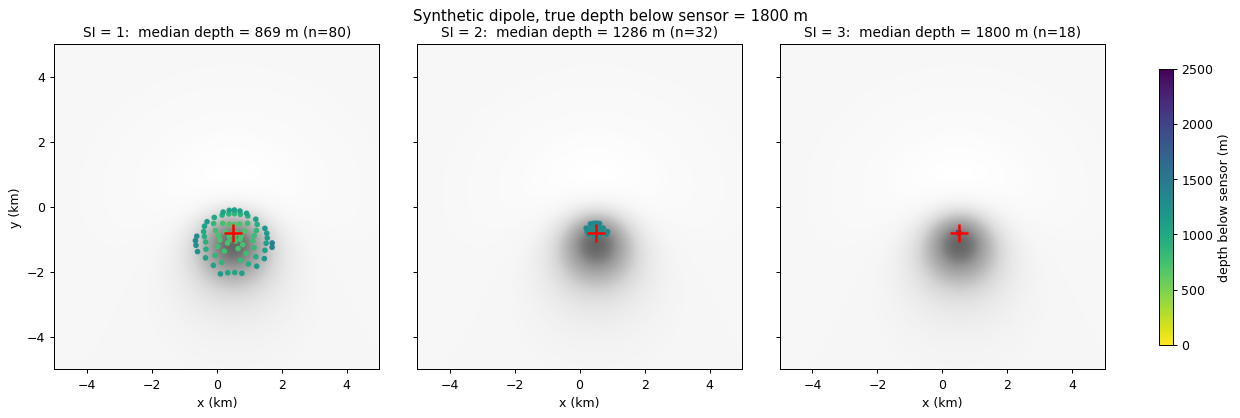

In [5]:
grids_syn = dict(T=T_syn, Tx=Tx_s, Ty=Ty_s, Tz=Tz_s, X=Xs, Y=Ys, Z=Zs)
true_depth = src['z0'] - (-300.0)

fig, axs = plt.subplots(1, 3, figsize=(14, 4.3), constrained_layout=True, sharey=True)
for ax, si in zip(axs, [1, 2, 3]):
    sol = accept(euler_moving_window(grids_syn, si=si, size=41, step=8), max_err_pct=10)
    ax.imshow(T_syn, extent=ext, cmap='Greys', alpha=0.6)
    sc = ax.scatter(sol.x0 / 1e3, sol.y0 / 1e3, c=sol.depth_sensor, s=12,
                    cmap='viridis_r', vmin=0, vmax=2500)
    ax.plot(src['x0'] / 1e3, src['y0'] / 1e3, 'r+', ms=14, mew=2)
    ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
    ax.set_title(f'SI = {si}:  median depth = {np.median(sol.depth_sensor):.0f} m '
                 f'(n={len(sol)})')
    ax.set_xlabel('x (km)')
axs[0].set_ylabel('y (km)')
fig.colorbar(sc, ax=axs, label='depth below sensor (m)', shrink=0.85)
fig.suptitle(f'Synthetic dipole, true depth below sensor = {true_depth:.0f} m', y=1.04)
plt.show()

With the correct SI (3), the solutions collapse onto the true source at the true
depth. With SI = 1 or 2 the horizontal position is still roughly right, but the
depth is badly **underestimated**: approximately in proportion to $N$, as
predicted. This is the most important practical lesson of Euler deconvolution:
**horizontal location is robust; depth is only as good as your SI.**

### Effect of noise

Real data contain noise, and $\partial T/\partial z$ amplifies it at high wavenumbers. Below we
add 0.5 nT of white noise and compare (a) naive derivatives with (b) derivatives
computed after a 100 m upward continuation. For (b) the observation surface moves
up by 100 m, so $z$ must change too.

We also add a **signal-strength criterion**: a window is used only if its mean
analytic signal $|A| = \sqrt{T_x^2+T_y^2+T_z^2}$ exceeds a threshold. Far from the source the windows see only
noise, and the least-squares problem happily returns precise-looking nonsense.

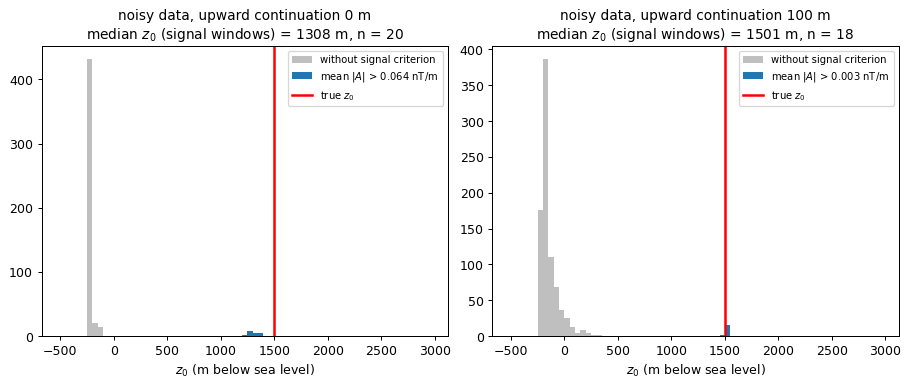

In [6]:
rng = np.random.default_rng(42)
T_noisy = T_syn + rng.normal(0, 0.5, T_syn.shape)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.2), constrained_layout=True)
for ax, up in zip(axs, [0.0, 100.0]):
    Tn = upward_continue(T_noisy, dx_s, dx_s, up) if up else T_noisy
    gx, gy, gz = gradients(T_noisy, dx_s, dx_s, up=up)
    g = dict(T=Tn, Tx=gx, Ty=gy, Tz=gz, X=Xs, Y=Ys, Z=Zs - up)
    # threshold: 3x the median analytic signal (a robust estimate of the noise floor)
    AS_MIN = 3 * np.median(np.sqrt(gx**2 + gy**2 + gz**2))
    raw = euler_moving_window(g, si=3, size=41, step=8)
    all_ok = accept(raw, max_err_pct=10)
    sol = accept(raw, max_err_pct=10, min_as=AS_MIN)
    bins = np.arange(-500, 3000, 50)
    ax.hist(all_ok.z0, bins=bins, color='0.75', label='without signal criterion')
    ax.hist(sol.z0, bins=bins, color='C0', label=f'mean $|A|$ > {AS_MIN:.3f} nT/m')
    ax.axvline(src['z0'], color='r', lw=2, label='true $z_0$')
    ax.set_title(f'noisy data, upward continuation {up:.0f} m\n'
                 f'median $z_0$ (signal windows) = {np.median(sol.z0):.0f} m, n = {len(sol)}')
    ax.set_xlabel('$z_0$ (m below sea level)'); ax.legend(fontsize=8)
plt.show()

Two lessons:

1. **Grey bars.** Windows that contain no anomaly still return "solutions", and
   many pass the uncertainty test. They pile up just below the sensor. They must
   be screened out by an independent criterion, such as signal strength or
   clustering (FitzGerald et al., 2004).
2. **Noise biases depth shallow.** Without stabilization, the high-wavenumber noise in
   $\partial T/\partial z$ makes the field look as if it varies faster than it really
   does. Euler interprets that as a *nearer* source, so the depth is underestimated
   by ~200 m. A 100 m upward continuation removes the bias, at the price of
   resolution for very shallow sources.

---
## Part 2 — Real data: USGS Earth MRI survey over the Viburnum Trend

### Geologic setting

The **St. Francois Mountains** of southeast Missouri are an inlier of
Mesoproterozoic (~1.48–1.44 Ga) rhyolitic volcanic rocks and granite. They are
exposed in a structural dome and surrounded by flat-lying Cambrian–Ordovician
sedimentary rocks (Lamotte Sandstone, Bonneterre Formation, and younger
carbonates and dolomites), which are essentially non-magnetic. Away from the
exposed core the Precambrian surface is buried under progressively thicker
Paleozoic cover.

Our study area is a 30 km × 50 km block on the **western flank of the dome**,
centred on the town of Viburnum (37.44–37.89° N, 91.39–91.04° W). It covers the
**Viburnum Trend**, one of the world's largest Mississippi Valley-type lead–zinc
districts, hosted in the Bonneterre Formation where it drapes over buried
Precambrian knobs. **No Precambrian rock crops out here.** Every magnetic anomaly
in the map comes from basement buried beneath hundreds of metres of sedimentary
cover, plus any magnetic intrusions within it.

The buried basement also hosts the **iron oxide–apatite (IOA) and iron
oxide–copper–cobalt–gold (IOCG) deposits** of the southeast Missouri iron province
(Pea Ridge, Pilot Knob, Bourbon, Boss–Bixby, …; USGS, n.d.). Magnetite-rich bodies produce some
of the strongest magnetic anomalies in the mid-continent. That is why the region
was the first target of the USGS Earth Mapping Resources Initiative (Earth MRI;
Day, 2019). For the magnetic and gravity framework of the district, see McCafferty
et al. (2016). Of these deposits, **Boss–Bixby** lies within our block, a few
kilometres west of the Viburnum Trend mines. It was discovered in 1956 by
drilling a *blind magnetic anomaly*. According to the Missouri DNR, the
deposit is overlain by **more than 1,000 ft (~300 m) of sedimentary rock**
(Missouri DNR, 2020). The deposit coordinates used on our maps are from Mindat.org
(n.d.).

**A testable expectation for Euler deconvolution:** the sources in this block
should sit at or below the base of the Paleozoic section, i.e. **a few hundred
metres or more below the ground surface**. Solutions at depths of only a few tens
of metres would be geologically implausible here. They point to noise or to a
structural index that is too small.

*(The 2018–19 survey deliberately left a hole over the exposed St. Francois core
around Ironton. That area is covered by an earlier USGS survey, McCafferty 2016,
https://doi.org/10.5066/F7B56GT8, which is a natural next dataset for comparing
"outcropping" vs. "buried" basement.)*

### The dataset

The file `data/semo_viburnum_mag.csv.gz` is a subset of the flight-line
database from:

> McCafferty, A.E., and Johnson, M.R., 2019, *Airborne magnetic and radiometric
> survey, southeast Missouri and western Illinois, 2018–2019*: U.S. Geological
> Survey data release, https://doi.org/10.5066/P9PBDSA1.

The flight-line file (`B478ARC_MAG191003.csv`, 6.75 GB) is distributed through the
USGS ScienceBase catalog (U.S. Geological Survey, 2019), and the survey
specifications below come from its metadata.

The survey was flown by Terraquest Ltd. for the USGS with three Cs-vapour
magnetometers (tail stinger plus two wing tips). Survey specifications:

* north–south flight lines **300 m** apart, east–west tie lines every 3000 m
* **117 m** mean terrain clearance (draped)
* 10 Hz sampling, about 7 m along-line

We keep only the north–south traverse lines inside our study area, decimated to
roughly one sample every 50 m. See `data/README.md` for the exact provenance and
processing.

In [7]:
df = pd.read_csv(DATA_FILE)
print(f'{len(df):,} observations on {df.LINE.nunique()} flight lines')
df.describe().T.round(3)

100,035 observations on 111 flight lines


,count,mean,std,min,25%,50%,75%,max
FID,100035.0,66620.754,11186.074,44895.600,56863.300,64916.000,76871.250,88716.600
X,100035.0,657051.585,8659.765,642186.000,649550.950,657188.900,664419.650,671911.600
Y,100035.0,4169999.664,14436.963,4145000.000,4157499.600,4170000.300,4182500.200,4194999.900
ALT,100035.0,468.739,34.359,362.200,447.900,474.500,494.300,567.100
RADAR,100035.0,111.673,21.642,49.800,96.100,108.700,124.600,229.300
DTM,100035.0,357.077,40.293,222.300,329.600,362.400,387.100,453.700
TMI,100035.0,51504.793,213.878,50967.240,51402.320,51457.160,51524.745,53781.720
TMI_ANOM,100035.0,-8.014,219.016,-510.480,-141.595,-21.330,58.750,2273.850
HG_EW,100035.0,0.006,0.111,-3.556,-0.023,0.001,0.028,1.914
HG_NS,100035.0,-0.005,0.144,-3.831,-0.028,-0.003,0.028,1.881


| Column | Meaning |
|---|---|
| `LINE` | flight line ID |
| `X`, `Y` | UTM zone 15N easting / northing (m, WGS 84) |
| `ALT` | GPS altitude of the aircraft (m above sea level) |
| `RADAR` | radar-altimeter terrain clearance (m) |
| `DTM` | terrain elevation (m above sea level) |
| `TMI` | final levelled total magnetic intensity (nT) |
| `TMI_ANOM` | `TMI` minus the IGRF, i.e. the total-field anomaly $\Delta T$ (nT) |
| `HG_EW`, `HG_NS` | measured horizontal gradients from the wing-tip/tail magnetometers (nT/m) |

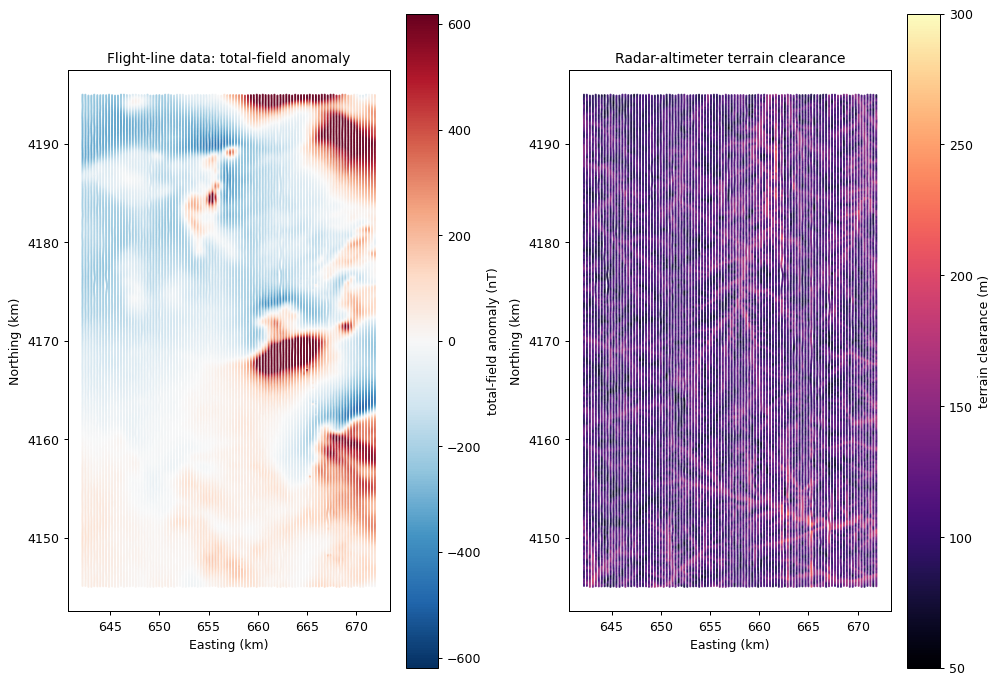

Median terrain clearance: 109 m;  median aircraft altitude: 474 m a.s.l.


In [8]:
fig, axs = plt.subplots(1, 2, figsize=(11, 7.5), constrained_layout=True)
v = np.percentile(np.abs(df.TMI_ANOM), 98)
d2 = df.iloc[::2]                                  # every other sample is plenty for a map
sc = axs[0].scatter(d2.X / 1e3, d2.Y / 1e3, c=d2.TMI_ANOM, s=0.3, cmap='RdBu_r', vmin=-v, vmax=v)
fig.colorbar(sc, ax=axs[0], label='total-field anomaly (nT)')
axs[0].set_title('Flight-line data: total-field anomaly')
sc = axs[1].scatter(d2.X / 1e3, d2.Y / 1e3, c=d2.RADAR, s=0.3, cmap='magma', vmin=50, vmax=300)
fig.colorbar(sc, ax=axs[1], label='terrain clearance (m)')
axs[1].set_title('Radar-altimeter terrain clearance')
for ax in axs:
    ax.set_aspect('equal'); ax.set_xlabel('Easting (km)'); ax.set_ylabel('Northing (km)')
plt.show()
print(f"Median terrain clearance: {df.RADAR.median():.0f} m;  "
      f"median aircraft altitude: {df.ALT.median():.0f} m a.s.l.")

### Gridding

Euler deconvolution and FFT derivatives both need a regular grid. The sampling is
very anisotropic: ~50 m along line but 300 m across lines. A common rule of thumb
is a grid cell of ¼–⅕ of the line spacing, so we use **75 m**. We interpolate with
`scipy.interpolate.griddata` (Clough–Tocher cubic) and blank cells more than 250 m
from any observation.

Professional packages use minimum-curvature or bi-directional gridding, which
handle line-oriented data better. Cubic Delaunay interpolation is good enough for
a demo, but expect some short-wavelength "boudinage" artifacts between lines.
These artifacts are one source of the noisy Euler solutions we will need to
reject.

We also grid the aircraft altitude (`ALT`), terrain (`DTM`), and the measured
horizontal gradients, so that each grid node has its own observation height
$z = -\text{ALT}$.

In [9]:
CELL = 75.0
x_min, x_max = df.X.min(), df.X.max()
y_min, y_max = df.Y.min(), df.Y.max()
gx = np.arange(np.ceil(x_min / CELL) * CELL, x_max, CELL)
gy = np.arange(np.ceil(y_min / CELL) * CELL, y_max, CELL)
GX, GY = np.meshgrid(gx, gy)
pts = df[['X', 'Y']].to_numpy()

dist, _ = cKDTree(pts).query(np.column_stack([GX.ravel(), GY.ravel()]))
blank = (dist > 250.0).reshape(GX.shape)

def to_grid(col):
    G = griddata(pts, df[col].to_numpy(), (GX, GY), method='cubic')
    G[blank] = np.nan
    return G

G = {c: to_grid(c) for c in ['TMI_ANOM', 'ALT', 'DTM', 'HG_EW', 'HG_NS']}
print(f'Grid: {GX.shape[1]} x {GX.shape[0]} nodes at {CELL:.0f} m;  '
      f'{np.isnan(G["TMI_ANOM"]).mean()*100:.1f}% blank')

Grid: 396 x 667 nodes at 75 m;  0.0% blank


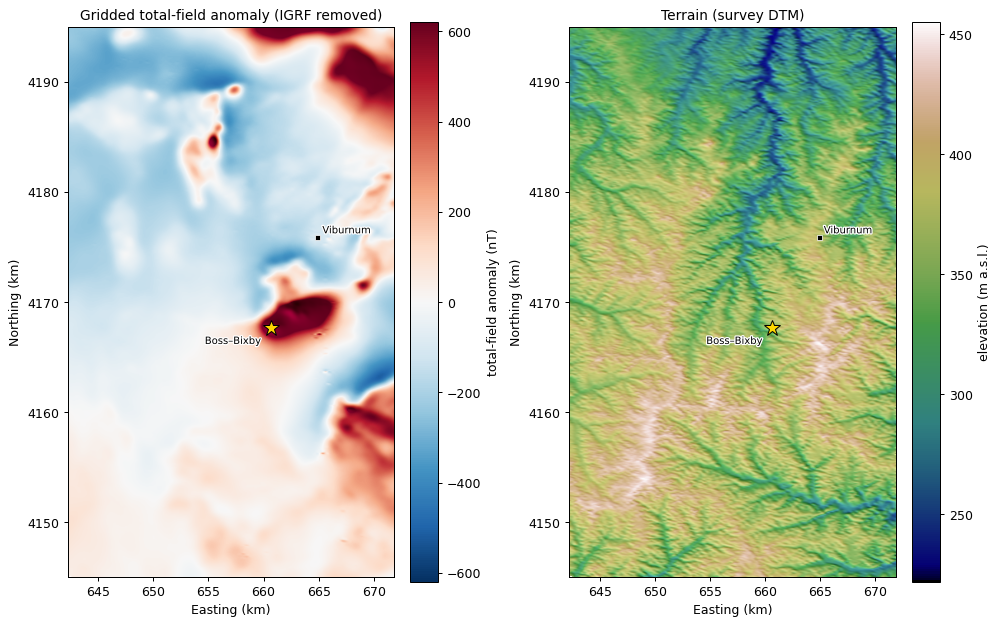

In [10]:
ext_km = np.array([gx[0], gx[-1], gy[0], gy[-1]]) / 1e3
ls = LightSource(azdeg=315, altdeg=35)

def shaded(ax, Z, cmap, vmin, vmax, label, fig, ve=1.0):
    """Colour image with hillshading (blank cells shown in white)."""
    Zf = np.where(np.isfinite(Z), Z, np.nanmedian(Z))
    rgb = ls.shade(Zf, cmap=plt.get_cmap(cmap), vert_exag=ve, blend_mode='soft',
                   vmin=vmin, vmax=vmax, dx=CELL, dy=CELL)
    rgb[~np.isfinite(Z)] = 1.0
    ax.imshow(rgb, extent=ext_km)
    fig.colorbar(plt.cm.ScalarMappable(Normalize(vmin, vmax), cmap), ax=ax, label=label, shrink=0.85)
    ax.set_xlabel('Easting (km)'); ax.set_ylabel('Northing (km)')

TOWNS = {  # approximate town locations, UTM 15N (m), for orientation only
    'Ironton': (709484, 4163784),
    'Fredericktown': (739016, 4160418),
    'Viburnum': (664882, 4175908),
    'Bismarck': (709203, 4182887),
    'Potosi': (694397, 4201033),
    'Annapolis': (703902, 4137363),
    'Centerville': (680641, 4145087),
}
# Boss–Bixby Fe–Cu–Co deposit: Mindat locality 37°38'32"N, 91°10'44"W -> UTM 15N
DEPOSITS = {'Boss–Bixby': (660669, 4167680)}

def add_towns(ax, color='k'):
    for name, (e, n) in DEPOSITS.items():
        ax.plot(e / 1e3, n / 1e3, '*', ms=13, color='gold', mec='k', mew=0.8, zorder=6)
        ax.annotate(name, (e / 1e3, n / 1e3), xytext=(-8, -13), textcoords='offset points',
                    fontsize=8, color='k', ha='right',
                    path_effects=[pe.withStroke(linewidth=2, foreground='w')])
    for name, (e, n) in TOWNS.items():
        if not (gx[0] <= e <= gx[-1] and gy[0] <= n <= gy[-1]):
            continue
        ax.plot(e / 1e3, n / 1e3, 's', ms=4, color=color, mec='w', mew=0.6)
        ax.annotate(name, (e / 1e3, n / 1e3), xytext=(4, 3), textcoords='offset points',
                    fontsize=8, color=color,
                    path_effects=[pe.withStroke(linewidth=2, foreground='w')])

fig, axs = plt.subplots(1, 2, figsize=(11, 7.5), constrained_layout=True)
VT = np.nanpercentile(np.abs(G['TMI_ANOM']), 98)     # colour limit for anomaly maps
shaded(axs[0], G['TMI_ANOM'], 'RdBu_r', -VT, VT, 'total-field anomaly (nT)', fig, ve=0.02)
axs[0].set_title('Gridded total-field anomaly (IGRF removed)')
shaded(axs[1], G['DTM'], 'gist_earth', np.nanmin(G['DTM']), np.nanmax(G['DTM']),
       'elevation (m a.s.l.)', fig, ve=3)
axs[1].set_title('Terrain (survey DTM)')
for ax in axs:
    add_towns(ax)
plt.show()

Compare the two maps. The magnetic anomalies show **no relationship to the
topography**. The drainage pattern is cut entirely into flat-lying Paleozoic
carbonates, and the magnetic sources lie beneath them. (Over the exposed St.
Francois Mountains, by contrast, anomalies follow the rhyolite and granite knobs
closely.) The anomalies are also relatively smooth, without the very short
wavelengths of outcropping magnetic rock. That is a qualitative hint of source
depth, and Euler deconvolution makes it quantitative.

The most prominent feature is the intense (> 2000 nT), elliptical high
south-west of Viburnum. It coincides with the **Boss–Bixby** deposit (gold star;
Mindat locality 37.642° N, 91.179° W). This is the blind magnetic anomaly whose
drilling discovered the deposit in 1956. Smaller
highs to the north-west and south-east, and the broad lows between them, mark
lithologic variation within the buried basement.

---
## Part 3 — Derivatives and the analytic signal

The FFT needs a complete grid, so blank cells are temporarily filled with their
nearest neighbour before filtering and blanked again afterwards. We apply a
modest **50 m upward continuation** before differentiating to suppress
gridding noise (Part 1). The observation surface is then $z = -(\text{ALT}+50)$.

The draped survey surface is not flat. The FFT vertical derivative assumes a
level surface, which is an approximation; differences in flight height of a
few tens of metres are small compared with the source depths we hope to resolve.

Look for the small, isolated spikes in the derivative maps along a north–south
line near 665 km E. Only the derivatives reveal them. They are probably cultural
sources (the Viburnum Trend has mines, mills, and power lines) or residual
spikes in the line data. Euler deconvolution turns each of them into a cluster of
spurious shallow solutions, which is a good reason to inspect derivative maps
before trusting any automatic method.

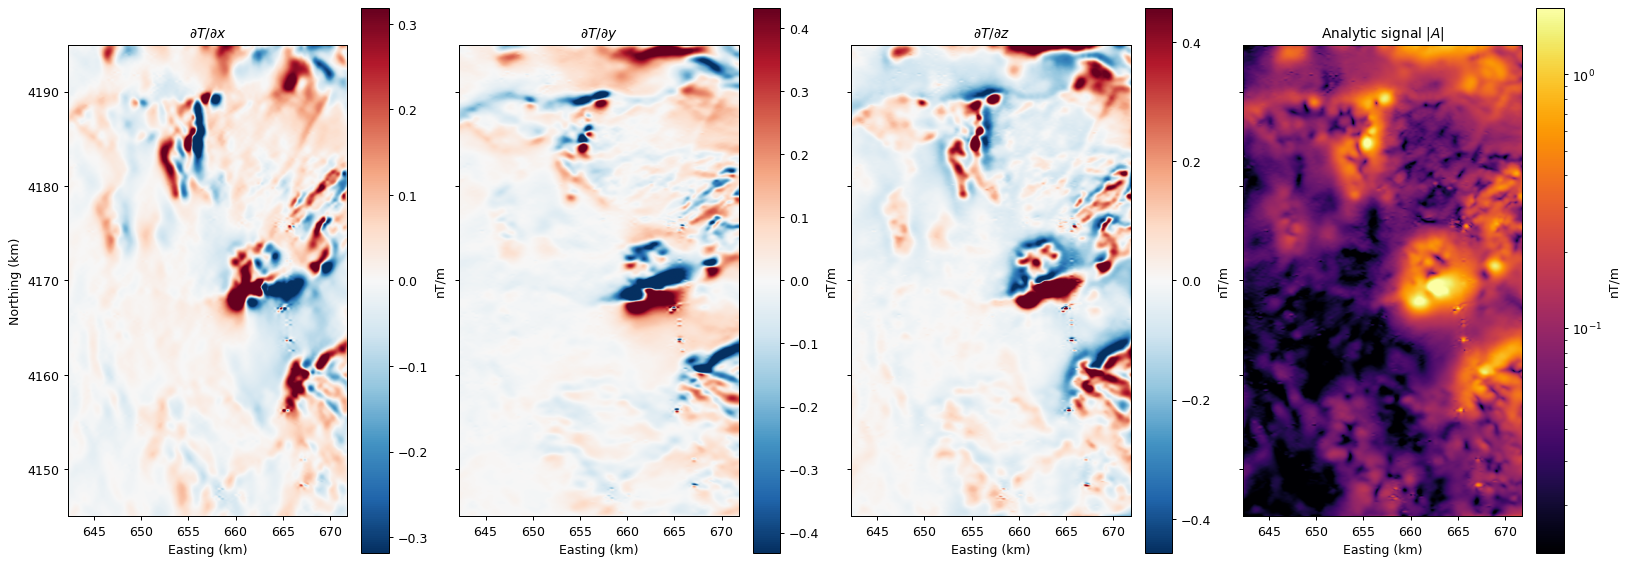

In [11]:
def fill_nearest(Z):
    """Fill NaNs with the nearest valid value (for FFT filtering only)."""
    m = np.isfinite(Z)
    tree = cKDTree(np.column_stack([GX[m], GY[m]]))
    _, idx = tree.query(np.column_stack([GX[~m], GY[~m]]))
    Zf = Z.copy(); Zf[~m] = Z[m][idx]
    return Zf

UP = 50.0
T_fill = fill_nearest(G['TMI_ANOM'])
T_up = upward_continue(T_fill, CELL, CELL, UP)
Tx, Ty, Tz = gradients(T_fill, CELL, CELL, up=UP)
for a in (T_up, Tx, Ty, Tz):
    a[blank] = np.nan
Z_obs = -(G['ALT'] + UP)                            # z positive down
AS = np.sqrt(Tx**2 + Ty**2 + Tz**2)                 # analytic-signal amplitude

fig, axs = plt.subplots(1, 4, figsize=(18, 7.2), constrained_layout=True, sharey=True)
for ax, F, ttl in zip(axs.flat, [Tx, Ty, Tz],
                      [r'$\partial T/\partial x$', r'$\partial T/\partial y$', r'$\partial T/\partial z$']):
    v = np.nanpercentile(np.abs(F), 98)
    im = ax.imshow(F, extent=ext_km, cmap='RdBu_r', vmin=-v, vmax=v)
    fig.colorbar(im, ax=ax, label='nT/m', shrink=0.85); ax.set_title(ttl)
im = axs[3].imshow(AS, extent=ext_km, cmap='inferno',
                      norm=LogNorm(vmin=np.nanpercentile(AS, 5),
                                                         vmax=np.nanpercentile(AS, 99.8)))
fig.colorbar(im, ax=axs[3], label='nT/m', shrink=0.85)
axs[3].set_title(r'Analytic signal $|A|$')
for ax in axs.flat:
    ax.set_xlabel('Easting (km)')
axs[0].set_ylabel('Northing (km)')
plt.show()

### Sanity check against the measured gradients

This survey **measured** the horizontal gradients directly with wing-tip and tail
magnetometers. Comparing them with our grid-derived $\partial T/\partial x$ and
$\partial T/\partial y$ checks both the gridding and the sign conventions. The measured
gradients are sampled 300 m apart across lines and are not upward-continued, so
we expect strong correlation, not perfect agreement.

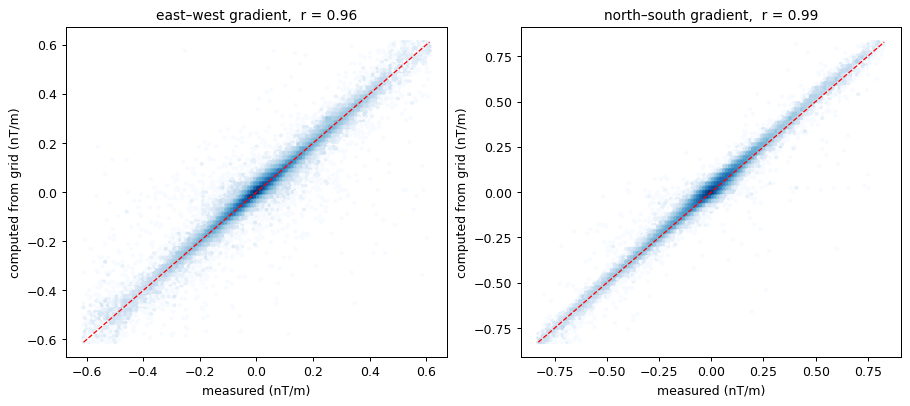

In [12]:
Tx0, Ty0, _ = gradients(T_fill, CELL, CELL, up=0.0)
m = np.isfinite(G['HG_EW']) & ~blank
fig, axs = plt.subplots(1, 2, figsize=(10, 4.4), constrained_layout=True)
for ax, calc, meas, lab in zip(axs, [Tx0, Ty0], [G['HG_EW'], G['HG_NS']],
                               ['east–west', 'north–south']):
    c, mm = calc[m], meas[m]
    r = np.corrcoef(c, mm)[0, 1]
    lim = np.percentile(np.abs(np.r_[c, mm]), 99.5)
    ax.hexbin(mm, c, gridsize=120, bins='log', cmap='Blues', extent=(-lim, lim, -lim, lim))
    ax.plot([-lim, lim], [-lim, lim], 'r--', lw=1)
    ax.set_xlabel('measured (nT/m)'); ax.set_ylabel('computed from grid (nT/m)')
    ax.set_title(f'{lab} gradient,  r = {r:.2f}')
plt.show()

---
## Part 4 — Moving-window Euler deconvolution

We now apply the Reid et al. (1990) algorithm to the whole grid.

**Window size.** The window must be large enough to capture the gradient
character of an anomaly, yet small enough that, ideally, it contains only one
source. Reid et al. (2014) note that sources deeper than about twice the window
size are poorly resolved. We use $W = 17$ cells (1.2 km, four line spacings),
which suits sources from about the surface to ~2 km depth. The windows step by 3
cells.

**Depth below ground.** Euler returns $z_0$ in our coordinate system, i.e. minus the
source elevation. We convert it to depth below the terrain surface at the window
centre: $d = z_0 + \text{DTM}$. This is equivalent to Seequent's "subtract the
instrument height from the sensor-to-source distance".

In [13]:
grids = dict(T=T_up, Tx=Tx, Ty=Ty, Tz=Tz, X=GX, Y=GY, Z=Z_obs)
WIN, STEP = 17, 3
dtm_interp = lambda x, y: griddata((GX[~blank], GY[~blank]), G['DTM'][~blank], (x, y), method='nearest')

# Signal criterion: ignore windows whose mean analytic signal is below the grid median
AS_MIN_REAL = np.nanpercentile(AS, 50)
print(f'Signal threshold: window-mean |A| > {AS_MIN_REAL:.4f} nT/m')

solutions = {}
for si in [0, 1, 2, 3]:
    raw = euler_moving_window(grids, si=si, size=WIN, step=STEP)
    acc = accept(raw, max_err_pct=15.0, min_as=AS_MIN_REAL)
    acc['elev'] = -acc.z0                                  # source elevation (m a.s.l.)
    acc['depth_bg'] = acc.z0 + dtm_interp(acc.xc, acc.yc)  # depth below ground (m)
    solutions[si] = acc
    print(f'SI={si}: {len(raw):6d} windows -> {len(acc):6d} accepted  '
          f'(median depth below ground {acc.depth_bg.median():6.0f} m, '
          f'IQR {acc.depth_bg.quantile(.25):.0f}–{acc.depth_bg.quantile(.75):.0f} m)')

Signal threshold: window-mean |A| > 0.0654 nT/m


SI=0:  27557 windows ->   4853 accepted  (median depth below ground    175 m, IQR 52–331 m)


SI=1:  27557 windows ->   4334 accepted  (median depth below ground    603 m, IQR 388–851 m)


SI=2:  27557 windows ->   2688 accepted  (median depth below ground    911 m, IQR 656–1296 m)


SI=3:  27557 windows ->   1648 accepted  (median depth below ground   1190 m, IQR 917–1632 m)


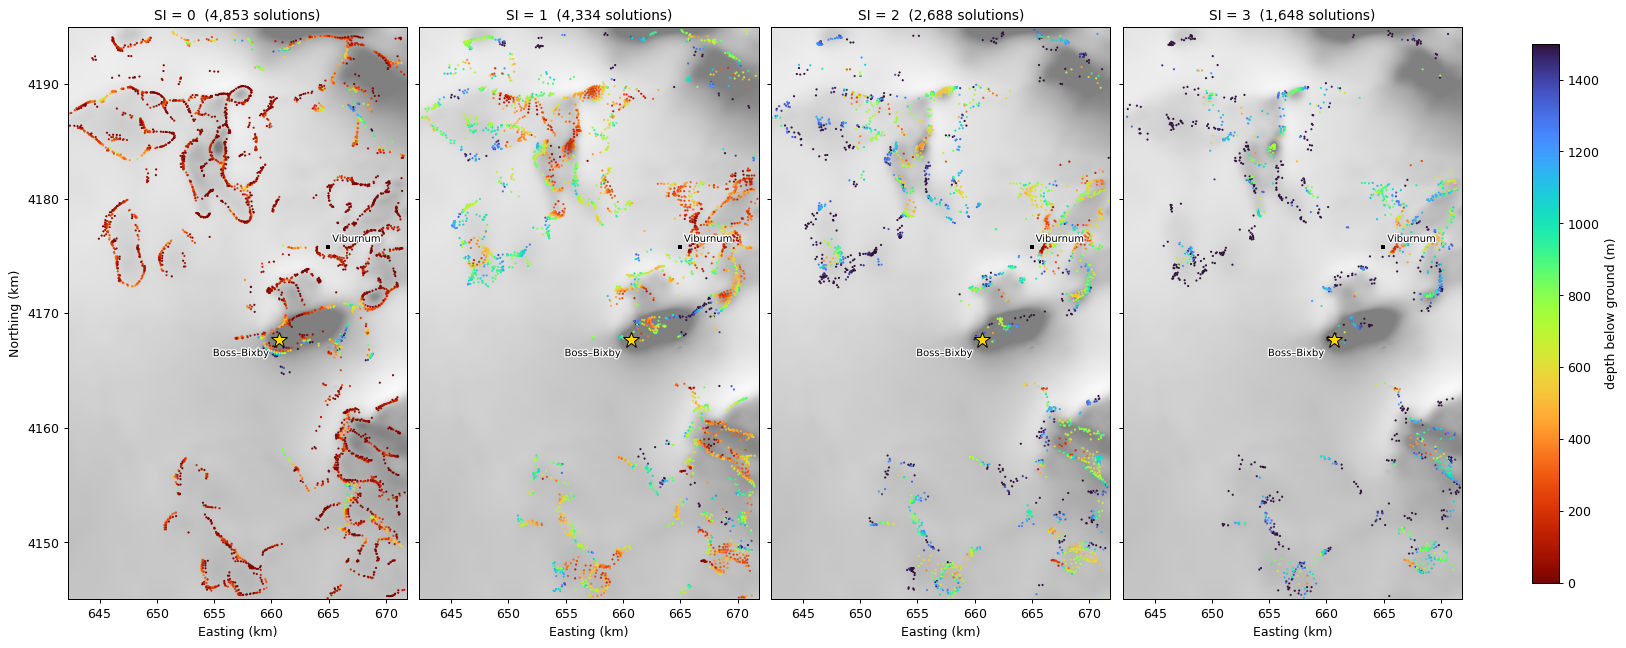

In [14]:
DEPTH_MAX = 1500
fig, axs = plt.subplots(1, 4, figsize=(18, 7.6), constrained_layout=True, sharey=True)
for ax, si in zip(axs.flat, [0, 1, 2, 3]):
    s = solutions[si].sort_values('depth_bg', ascending=False)   # shallow on top
    ax.imshow(T_up, extent=ext_km, cmap='Greys', vmin=-VT, vmax=VT, alpha=0.5)
    sc = ax.scatter(s.x0 / 1e3, s.y0 / 1e3, c=s.depth_bg, s=3, cmap='turbo_r',
                    vmin=0, vmax=DEPTH_MAX, lw=0)
    add_towns(ax)
    ax.set_xlim(ext_km[:2]); ax.set_ylim(ext_km[2:])
    ax.set_title(f'SI = {si}  ({len(s):,} solutions)')
    ax.set_xlabel('Easting (km)')
axs[0].set_ylabel('Northing (km)')
fig.colorbar(sc, ax=axs, label='depth below ground (m)', shrink=0.8)
plt.show()

**What to look for**

* **Clustering:** good solutions line up along contacts, dikes and the edges of
  magnetic bodies, or cluster tightly on compact sources. Isolated solutions are
  usually noise.
* **SI dependence:** the *pattern* (horizontal positions) barely changes between
  panels, but the *colours* (depths) shift steadily deeper as SI increases. This
  is the same SI–depth trade-off we saw in the synthetic.
* **Geology:** the basement here is buried beneath ≳300 m of Paleozoic rocks. An SI
  that puts most solutions at a few tens of metres depth is physically implausible.
  An SI that puts the basement surface at a few hundred metres is consistent with
  the drilling at Boss–Bixby and across the Viburnum Trend.

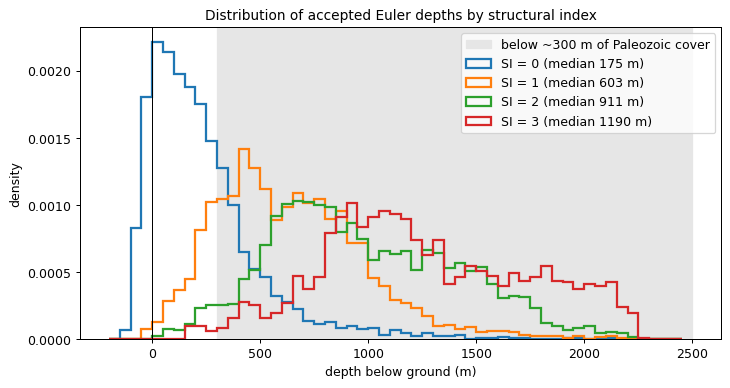

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.2), constrained_layout=True)
bins = np.arange(-200, 2500, 50)
ax.axvspan(300, 2500, color='0.9', zorder=0, label='below ~300 m of Paleozoic cover')
for si in [0, 1, 2, 3]:
    ax.hist(solutions[si].depth_bg, bins=bins, histtype='step', lw=1.8, density=True,
            label=f'SI = {si} (median {solutions[si].depth_bg.median():.0f} m)')
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('depth below ground (m)'); ax.set_ylabel('density')
ax.set_title('Distribution of accepted Euler depths by structural index')
ax.legend()
plt.show()

---
## Part 5 — Visualizing sources by depth

### 5a. Depth-binned maps

To read a depth map, split the solutions into depth slices. We use SI = 1, which
is appropriate for the dike- and sheet-like volcanic units and the edges of the
basement blocks, and plot each slice separately.

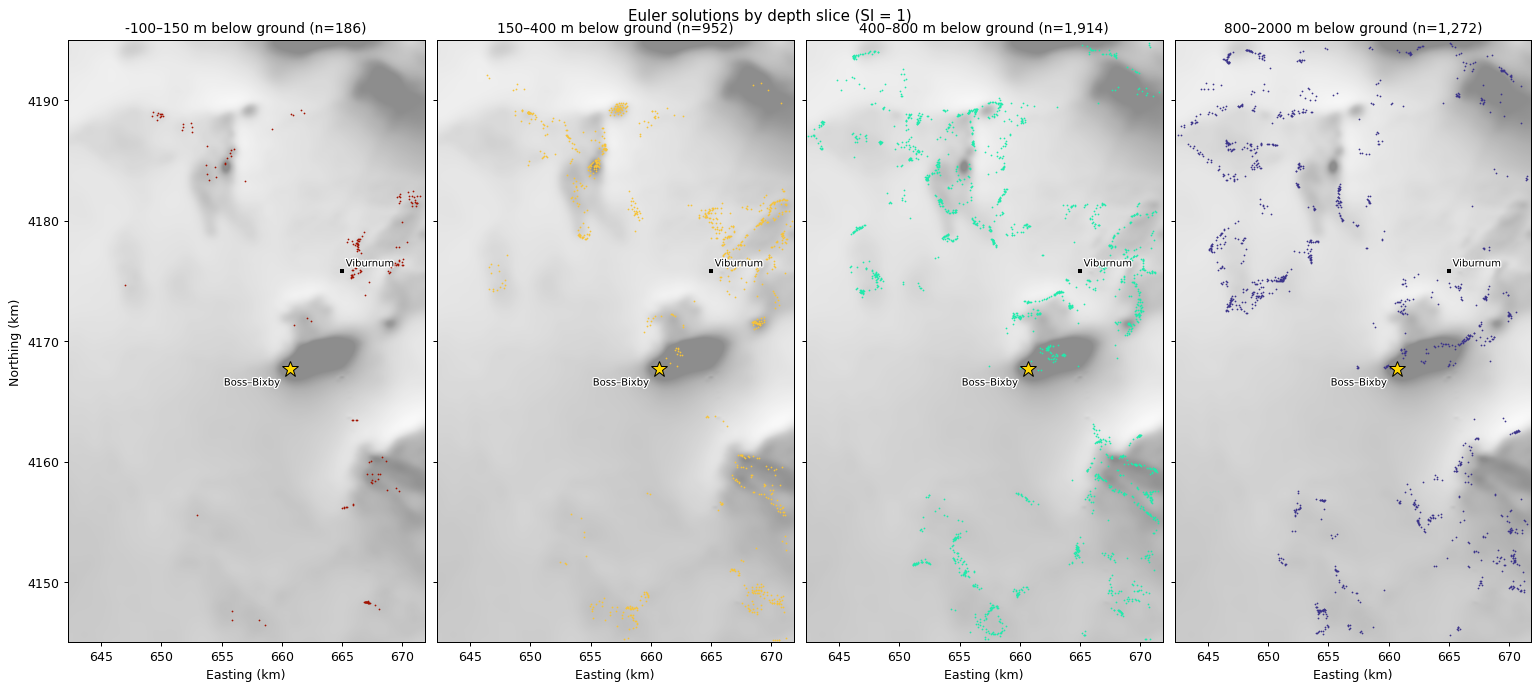

In [16]:
SI_VIEW = 1
s = solutions[SI_VIEW]
slices = [(-100, 150), (150, 400), (400, 800), (800, 2000)]
fig, axs = plt.subplots(1, 4, figsize=(17, 7.2), constrained_layout=True, sharey=True)
for ax, (d0, d1), col in zip(axs, slices, plt.cm.turbo_r(np.linspace(0.05, 0.95, 4))):
    ss = s[(s.depth_bg >= d0) & (s.depth_bg < d1)]
    ax.imshow(T_up, extent=ext_km, cmap='Greys', vmin=-VT, vmax=VT, alpha=0.45)
    ax.scatter(ss.x0 / 1e3, ss.y0 / 1e3, s=2, color=col, lw=0)
    add_towns(ax)
    ax.set_xlim(ext_km[:2]); ax.set_ylim(ext_km[2:])
    ax.set_title(f'{d0}–{d1} m below ground (n={len(ss):,})'); ax.set_xlabel('Easting (km)')
axs[0].set_ylabel('Northing (km)')
fig.suptitle(f'Euler solutions by depth slice (SI = {SI_VIEW})', y=1.03)
plt.show()

### 5b. Gridded "depth-to-magnetic-source" surface

A common product is a smoothed map of the **median depth of the solutions in each
cell** of a coarse grid. Because Euler solutions mark the *tops and edges* of
magnetic bodies, this map gives a first-order estimate of depth to magnetic
basement. That is exactly the quantity that should increase where Paleozoic cover
thickens.

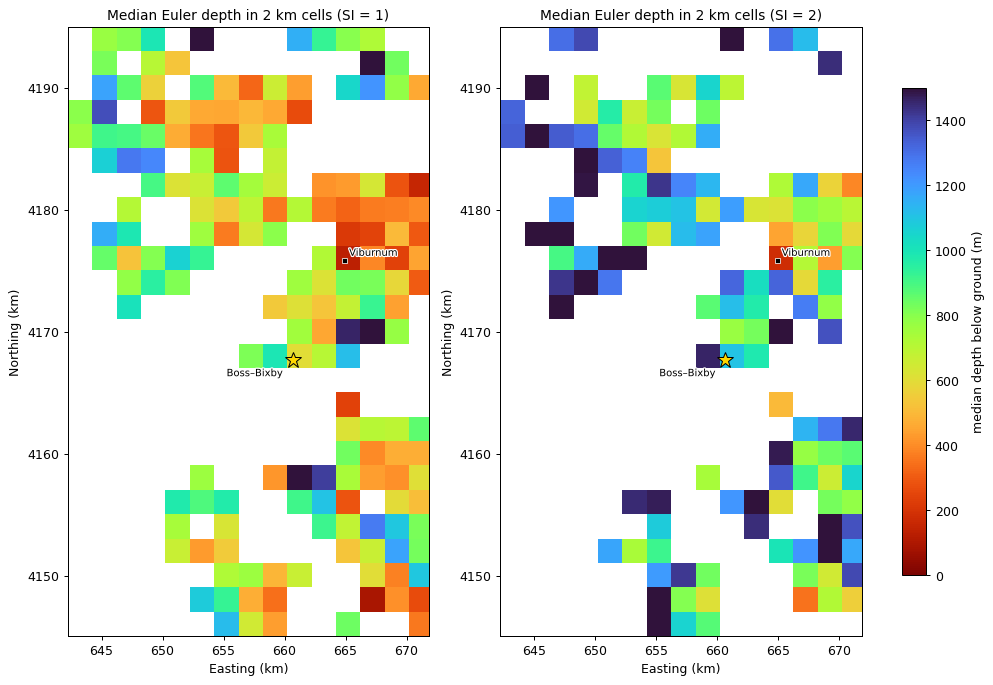

In [17]:
def binned_median(x, y, val, cell=2000.0, min_count=5):
    xe = np.arange(gx[0], gx[-1] + cell, cell); ye = np.arange(gy[0], gy[-1] + cell, cell)
    ix = np.digitize(x, xe) - 1; iy = np.digitize(y, ye) - 1
    M = np.full((len(ye) - 1, len(xe) - 1), np.nan)
    tab = pd.DataFrame(dict(ix=ix, iy=iy, v=val)).groupby(['iy', 'ix']).v.agg(['median', 'size'])
    tab = tab[tab['size'] >= min_count]
    for (j, i), row in tab.iterrows():
        if 0 <= j < M.shape[0] and 0 <= i < M.shape[1]:
            M[j, i] = row['median']
    return xe, ye, M

fig, axs = plt.subplots(1, 2, figsize=(11, 7.5), constrained_layout=True)
for ax, si in zip(axs, [1, 2]):
    s = solutions[si]
    xe, ye, M = binned_median(s.x0.values, s.y0.values, s.depth_bg.values)
    im = ax.pcolormesh(xe / 1e3, ye / 1e3, M, cmap='turbo_r', vmin=0, vmax=DEPTH_MAX)
    add_towns(ax, color='k')
    ax.set_aspect('equal'); ax.set_xlim(ext_km[:2]); ax.set_ylim(ext_km[2:])
    ax.set_title(f'Median Euler depth in 2 km cells (SI = {si})')
    ax.set_xlabel('Easting (km)'); ax.set_ylabel('Northing (km)')
fig.colorbar(im, ax=axs, label='median depth below ground (m)', shrink=0.8)
plt.show()

### 5c. Cross-section

An east–west slice through the middle of the area, with solutions from a 3 km wide
swath projected onto it, shows the sources in profile beneath the topography and
the flight surface.

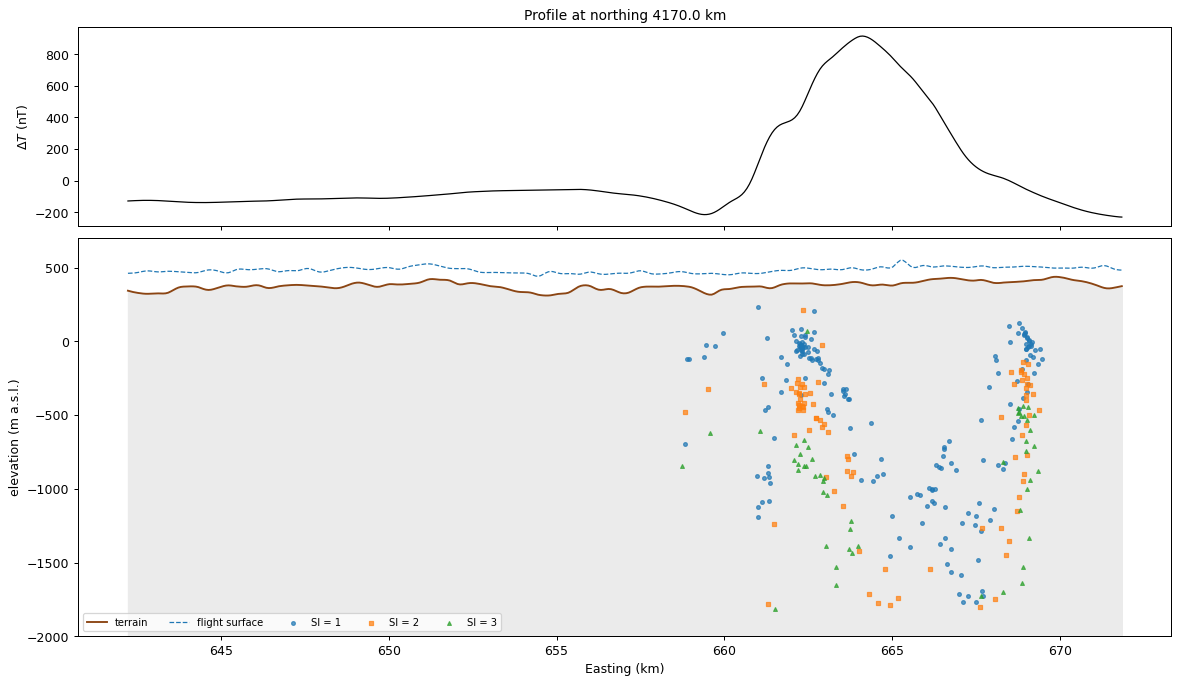

In [18]:
y_sec = np.nanmedian(GY)
swath = 1500.0
row = np.argmin(np.abs(gy - y_sec))

fig, axs = plt.subplots(2, 1, figsize=(13, 7.5), constrained_layout=True, sharex=True,
                        gridspec_kw=dict(height_ratios=[1, 2]))
axs[0].plot(gx / 1e3, T_up[row], 'k', lw=1)
axs[0].set_ylabel('$\\Delta T$ (nT)'); axs[0].set_title(f'Profile at northing {y_sec/1e3:.1f} km')
axs[1].fill_between(gx / 1e3, G['DTM'][row], -3000, color='0.92', zorder=0)
axs[1].plot(gx / 1e3, G['DTM'][row], color='saddlebrown', lw=1.5, label='terrain')
axs[1].plot(gx / 1e3, G['ALT'][row], color='C0', lw=1, ls='--', label='flight surface')
for si, mk in [(1, 'o'), (2, 's'), (3, '^')]:
    s = solutions[si]
    ss = s[np.abs(s.y0 - y_sec) < swath]
    axs[1].scatter(ss.x0 / 1e3, ss.elev, s=9, marker=mk, alpha=0.7, label=f'SI = {si}')
axs[1].set_ylim(-2000, 700)
axs[1].set_ylabel('elevation (m a.s.l.)'); axs[1].set_xlabel('Easting (km)')
axs[1].legend(loc='lower left', ncol=5, fontsize=8)
plt.show()

### 5d. 3-D view

Finally, a 3-D scatter of the SI = 1 solutions (elevation vs. map position) over
the terrain surface. Drag to rotate if you run the notebook with an interactive
backend (`%matplotlib widget`).

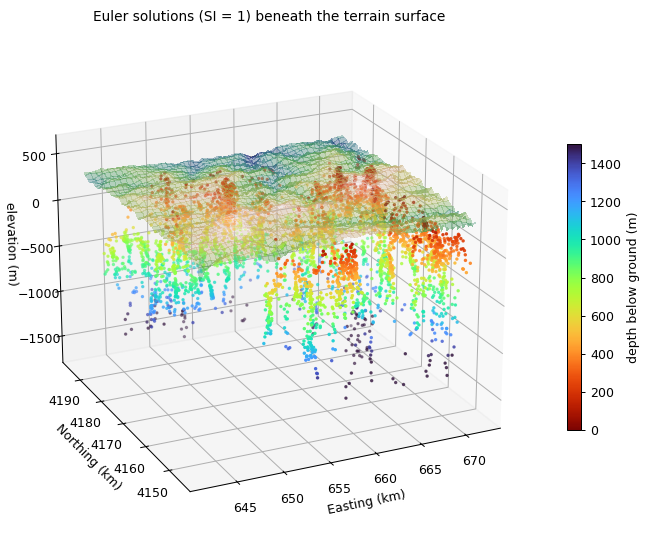

In [19]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
s = solutions[1]
s = s[s.depth_bg < 2000]
s = s.sample(min(len(s), 6000), random_state=0)
fig = plt.figure(figsize=(11, 7.5))
ax = fig.add_subplot(projection='3d')
k = 8
ax.plot_surface(GX[::k, ::k] / 1e3, GY[::k, ::k] / 1e3, np.nan_to_num(G['DTM'][::k, ::k], nan=np.nanmin(G['DTM'])),
                cmap='gist_earth', alpha=0.35, linewidth=0, antialiased=False)
sc = ax.scatter(s.x0 / 1e3, s.y0 / 1e3, s.elev, c=s.depth_bg, cmap='turbo_r', vmin=0,
                vmax=DEPTH_MAX, s=3)
ax.set_xlabel('Easting (km)'); ax.set_ylabel('Northing (km)'); ax.set_zlabel('elevation (m)')
ax.set_zlim(-1800, 700); ax.view_init(elev=22, azim=-115)
fig.colorbar(sc, ax=ax, shrink=0.55, label='depth below ground (m)')
ax.set_title('Euler solutions (SI = 1) beneath the terrain surface')
plt.show()

---
## Part 6 — Targeted Euler deconvolution (the UX-Detect workflow)

UXO surveys and many mineral targeting studies look for **discrete, compact
sources**. A moving window over the whole grid is not needed there. Instead,
Seequent's *UX-Detect → Calculate depths and weights (Euler)* tool (Seequent, 2025):

1. starts from a list of **picked targets**, usually peaks of the analytic signal;
2. centres a square window on each target, with the size set from a *target size*
   channel;
3. solves Euler's equation by least squares for $(x_0, y_0, z_0, B)$ using every point in
   the window, **weighted inversely by distance from the window centre**;
4. reports `X`, `Y`, `Mag_Depth` (depth below ground, obtained by subtracting the
   instrument height), `Bkgrd_fld`, and `Depth_Err` (depth uncertainty as % of depth);
5. uses a user-chosen SI. The UX-Detect table suggests 3 (or 2.7) for compact
   ordnance-like objects.

(It also converts the analytic-signal amplitude and depth to an "apparent weight"
via an empirical table, based on Pennella (1982) and Pawlowski et al. (1995) as
cited by Seequent (2025). That step is specific to steel ordnance and we skip it.)

We reproduce steps 1–4 for the iron-district anomalies. Because these
magnetite bodies are far larger than a shell and sit hundreds of metres deep, we
use larger windows (2.6 km). We report results for SI = 1 (sheet / edge of a
large body), SI = 2 (pipe-like), and SI = 3 (compact body), which bracket the
plausible geometries of the IOA bodies.

In [20]:
# 1. Pick targets: local maxima of the analytic signal above the 99th percentile.
AS_f = np.where(np.isfinite(AS), AS, 0.0)
peak = (AS_f == maximum_filter(AS_f, size=27)) & (AS_f > np.nanpercentile(AS, 99.0))
jj, ii = np.nonzero(peak)
half = 17                                            # 35 x 35 cells = 2.6 km window
inside = (jj >= half) & (jj < AS.shape[0] - half) & (ii >= half) & (ii < AS.shape[1] - half)
jj, ii = jj[inside], ii[inside]
print(f'{len(jj)} analytic-signal targets picked')

def targeted_euler(jj, ii, si, half):
    """Distance-weighted Euler solution in a (2*half+1)^2 window centred on each target."""
    sl = lambda a: np.stack([a[j - half:j + half + 1, i - half:i + half + 1].ravel()
                             for j, i in zip(jj, ii)])
    W = {k: sl(grids[k]) for k in ('T', 'Tx', 'Ty', 'Tz', 'X', 'Y', 'Z')}
    xc, yc = GX[jj, ii], GY[jj, ii]
    r = np.hypot(W['X'] - xc[:, None], W['Y'] - yc[:, None])
    w = 1.0 / np.maximum(r, CELL)                     # inverse-distance weights
    good = np.isfinite(sum(W.values()))
    for k in W:
        W[k] = np.where(good, W[k], 0.0)
    w = np.where(good, w, 0.0)                        # blank cells get zero weight
    sol = euler_solve(W['T'], W['Tx'], W['Ty'], W['Tz'], W['X'], W['Y'], W['Z'], si, w=w)
    out = pd.DataFrame(dict(Target_ID=np.arange(1, len(jj) + 1), X=sol['x0'], Y=sol['y0']))
    zc = Z_obs[jj, ii]
    out['Mag_Depth'] = sol['z0'] + dtm_interp(xc, yc)          # depth below ground
    out['Bkgrd_fld'] = sol['base']
    out['Depth_Err'] = 100 * sol['sz'] / (sol['z0'] - zc)      # % of depth below sensor
    out['AS_peak'] = AS[jj, ii]
    out['offset_m'] = np.hypot(sol['x0'] - xc, sol['y0'] - yc)
    return out

tgt = {si: targeted_euler(jj, ii, si, half) for si in (1, 2, 3)}
tab = tgt[3][['Target_ID', 'X', 'Y', 'AS_peak']].copy()
for si in (1, 2, 3):
    tab[f'Mag_Depth_SI{si}'] = tgt[si].Mag_Depth
    tab[f'Depth_Err_SI{si}'] = tgt[si].Depth_Err
tab['Bkgrd_fld_SI3'] = tgt[3].Bkgrd_fld
tab.sort_values('AS_peak', ascending=False).round(1).head(15)

9 analytic-signal targets picked


,Target_ID,X,Y,AS_peak,Mag_Depth_SI1,Depth_Err_SI1,Mag_Depth_SI2,Depth_Err_SI2,Mag_Depth_SI3,Depth_Err_SI3,Bkgrd_fld_SI3
5,6,662213.9,4169470.9,3.6,466.2,1.2,900.1,0.9,1334.1,0.8,583.1
7,8,655556.6,4184601.3,2.7,207.3,1.6,520.0,1.0,832.8,0.8,-61.5
4,5,660501.4,4167756.0,2.2,592.1,2.2,1038.4,1.8,1484.8,1.6,390.3
3,4,664378.5,4168822.5,1.6,198.9,8.8,406.6,8.0,614.2,7.7,158.8
8,9,657125.8,4189371.6,1.5,210.9,2.0,537.2,1.0,863.6,0.7,-232.1
1,2,667558.5,4160804.0,1.5,345.5,2.3,720.4,2.0,1095.3,1.9,193.0
6,7,669077.9,4171459.7,1.5,255.1,1.7,592.4,1.0,929.7,0.8,-7.0
0,1,666115.3,4156728.7,1.1,104.5,5.4,320.8,4.7,537.0,4.4,34.4
2,3,666027.7,4163601.9,1.0,-18.4,12.9,94.5,9.9,207.3,8.8,-75.7


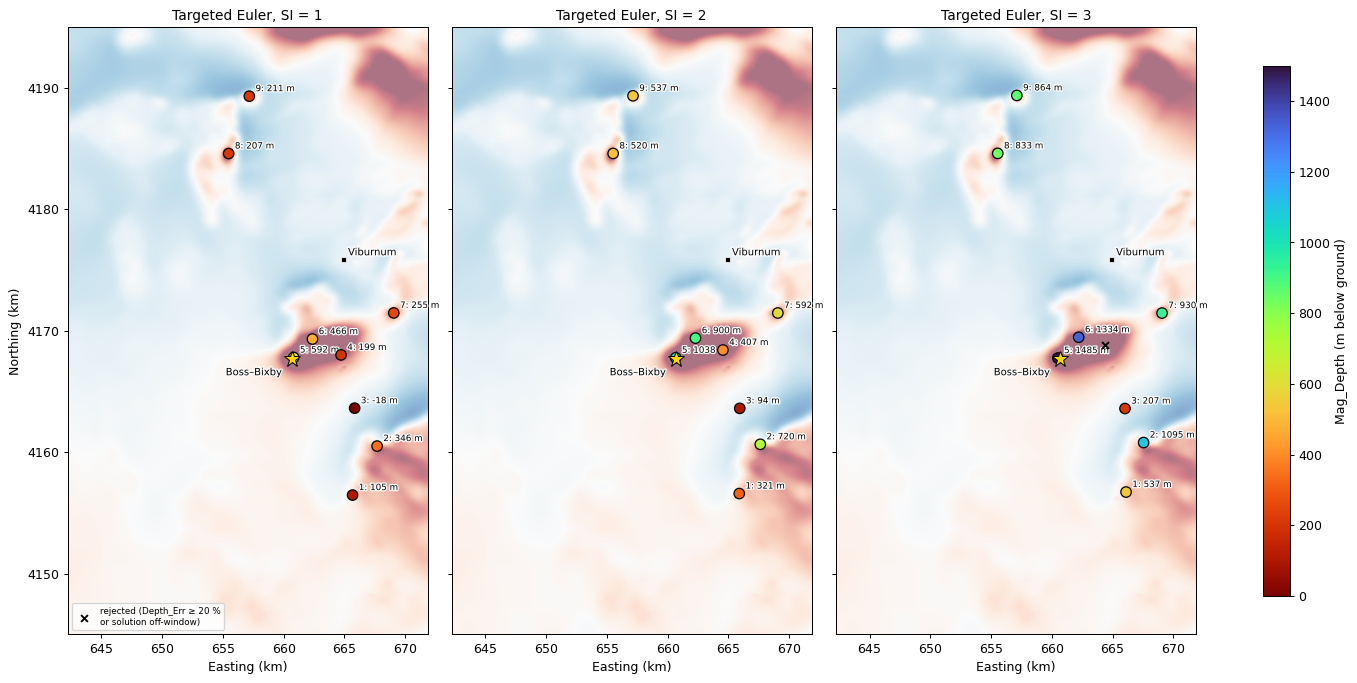

In [21]:
fig, axs = plt.subplots(1, 3, figsize=(15, 7.6), constrained_layout=True, sharey=True)
for ax, si in zip(axs, (1, 2, 3)):
    ax.imshow(T_up, extent=ext_km, cmap='RdBu_r', vmin=-VT, vmax=VT, alpha=0.55)
    t = tgt[si]
    ok = (t.Depth_Err < 20) & (t.offset_m < 1500) & (t.Mag_Depth > -100)
    sc = ax.scatter(t.X[ok] / 1e3, t.Y[ok] / 1e3, c=t.Mag_Depth[ok], cmap='turbo_r', vmin=0,
                    vmax=DEPTH_MAX, s=70, edgecolor='k', zorder=5)
    ax.scatter(t.X[~ok] / 1e3, t.Y[~ok] / 1e3, marker='x', c='k', s=30, zorder=5,
               label='rejected (Depth_Err ≥ 20 %\nor solution off-window)')
    for _, rr in t[ok].iterrows():
        ax.annotate(f'{int(rr.Target_ID)}: {rr.Mag_Depth:.0f} m', (rr.X / 1e3, rr.Y / 1e3),
                    xytext=(5, 4), textcoords='offset points', fontsize=7,
                    path_effects=[pe.withStroke(linewidth=2, foreground='w')])
    add_towns(ax)
    ax.set_title(f'Targeted Euler, SI = {si}'); ax.set_xlabel('Easting (km)')
    ax.set_xlim(ext_km[:2]); ax.set_ylim(ext_km[2:])
axs[0].set_ylabel('Northing (km)')
axs[0].legend(loc='lower left', fontsize=7)
fig.colorbar(sc, ax=axs, label='Mag_Depth (m below ground)', shrink=0.8)
plt.show()

The targeted solutions give one depth per anomaly, which is easy to tabulate,
rank, and follow up with drilling or forward modelling (M5). They inherit every
assumption of the moving-window method, though.

**Boss–Bixby as a benchmark.** Two targets sit on the Boss–Bixby anomaly, next to
the star. Their apparent depths are roughly 450–600 m (SI = 1), 0.9–1.0 km (SI = 2),
and 1.3–1.5 km (SI = 3). Drilling found the deposit beneath more than ~300 m of
Paleozoic cover. All three are therefore "consistent" with the minimum cover
thickness, but they mean different things. The SI = 3 depth approximates the
*centre* of an equivalent compact body. SI = 1 tracks the *top and edges* of a body
that is several kilometres across, which is large compared with its depth.

Note also that `Depth_Err` is only 1–2 % for **every** SI. The formal uncertainty
measures how well the data satisfy Euler's equation *for the SI you chose*. It
does not tell you whether that SI is correct. Choosing the SI is a geological
decision, informed by clustering behaviour and independent constraints such as
drilling.

---
## Discussion

**Strengths of Euler deconvolution**

* It is fast, automatic, and linear: each window is a 4×4 least-squares problem.
* It needs no assumption about the **magnetization direction**, so no RTP is
  required and remanence does not bias the source location.
* Horizontal source locations are robust, which makes it excellent for mapping
  contacts, dikes, and faults.

**Limitations and avoidable errors** (Reid et al., 2014; Reid & Thurston, 2014)

* **The depth scales with the assumed SI.** Using the "wrong" SI is the main source
  of bias. Use several SIs and look for the one that gives the tightest clustering.
  Alternatively, estimate SI as an extra unknown (Barbosa et al., 1999), or use
  extended Euler (Mushayandebvu et al., 2001).
* **Interfering sources** in one window violate the single-source assumption. The
  solutions they produce can look precise (small $\sigma_{z_0}$) and still be wrong.
* **Window size** limits the depth range. Windows that are too small cannot resolve
  deep sources. Windows that are too large mix sources together.
* The **vertical derivative amplifies noise and gridding artifacts**, and the
  draped, non-level survey surface violates the FFT's flat-surface assumption.
  Both make shallow, scattered "noise" solutions more likely.
* Finite real bodies are not homogeneous. Their effective SI changes with
  distance. SI = 0 for a contact strictly requires a modified equation (Reid &
  Thurston, 2014).

**Acceptance criteria are a choice.** The 15 % depth tolerance, the window-offset
test, and the depth/window ratio are common defaults, not laws. Changing them
changes the picture. Always say which criteria you used.

---
## Exercises

1. **Structural index.** Pick a distinct compact anomaly (e.g. a top-5 target in the
   Part 6 table). Run targeted Euler for SI = 1, 1.5, 2, 2.5, 3. Plot the estimated
   depth and `Depth_Err` vs. SI. Is there an SI that minimizes the uncertainty? How
   does the depth scale with SI?
2. **Window size.** Repeat Part 4 with `WIN = 9` and `WIN = 33`. How do the number
   of accepted solutions and the depth histogram change? Relate your answer to the
   rule of thumb about maximum resolvable depth.
3. **Stabilization.** Set `UP = 0` and then `UP = 150` m. What happens to the
   shallow (< 100 m) solutions? Explain using the |k| filter from M6.5.
4. **Synthetic remanence.** In Part 1, give the dipole a remanent magnetization
   direction (e.g. `inc=-30, dec=150`) while keeping `f_inc, f_dec` fixed. Show that
   the Euler location is unchanged even though the anomaly shape changes
   completely.
5. **Geology.** Using Part 5b, describe how the depth to magnetic sources varies
   across the block, e.g. around Boss–Bixby compared with the north-west and
   south-east corners. What independent data (drill holes, structure-contour maps
   of the top of the Precambrian) would you use to test whether these depths
   represent the top of the basement? *Extension:* repeat the analysis with the
   2016 Ironton survey (McCafferty, 2016), where the basement crops out.

---
## References

* Barbosa, V.C.F., Silva, J.B.C., and Medeiros, W.E., 1999, Stability analysis and improvement of structural index estimation in Euler deconvolution: *Geophysics*, 64(1), 48–60.
* Blakely, R.J., 1995, *Potential Theory in Gravity and Magnetic Applications*: Cambridge University Press.
* Day, W.C., 2019, The Earth Mapping Resources Initiative (Earth MRI): Mapping the Nation's critical mineral resources: U.S. Geological Survey Fact Sheet 2019–3007, https://doi.org/10.3133/fs20193007.
* FitzGerald, D., Reid, A., and McInerney, P., 2004, New discrimination techniques for Euler deconvolution: *Computers & Geosciences*, 30(5), 461–469.
* McCafferty, A.E., 2016, Airborne magnetic and radiometric survey, Ironton, Missouri area: U.S. Geological Survey data release, https://doi.org/10.5066/F7B56GT8.
* McCafferty, A.E., and Johnson, M.R., 2019, Airborne magnetic and radiometric survey, southeast Missouri and western Illinois, 2018–2019: U.S. Geological Survey data release, https://doi.org/10.5066/P9PBDSA1.
* McCafferty, A.E., Phillips, J.D., and Driscoll, R.L., 2016, Magnetic and gravity gradiometry framework for Mesoproterozoic iron oxide–apatite and iron oxide–copper–gold deposits, southeast Missouri: *Economic Geology*, 111(8), 1859–1882.
* Mindat.org, n.d., Boss–Bixby iron-copper deposit, Dent County, Missouri, USA: https://www.mindat.org/loc-272694.html (locality coordinates; accessed November 2026).
* Missouri Department of Natural Resources (Missouri DNR), 2020, Cobalt: fact sheet PUB2893, https://dnr.mo.gov/print/document-search/pub2893 (Boss deposit cover thickness).
* Mushayandebvu, M.F., van Driel, P., Reid, A.B., and Fairhead, J.D., 2001, Magnetic source parameters of two-dimensional structures using extended Euler deconvolution: *Geophysics*, 66(3), 814–823.
* Pawlowski, J., Lewis, R., Dobush, T., and Valleau, N., 1995, An integrated approach for measuring and processing geophysical data for the detection of unexploded ordnance: *Proceedings of SAGEEP 1995*, Orlando, Florida (cited by Seequent, 2025).
* Pennella, J., 1982, Magnetometer techniques in the detection of projectiles: NAVEODTECHCEN Technical Report TR-239, Naval Explosive Ordnance Disposal Technology Center, Indian Head, Maryland (cited by Seequent, 2025).
* Reid, A.B., Allsop, J.M., Granser, H., Millett, A.J., and Somerton, I.W., 1990, Magnetic interpretation in three dimensions using Euler deconvolution: *Geophysics*, 55(1), 80–91.
* Reid, A.B., and Thurston, J.B., 2014, The structural index in gravity and magnetic interpretation: Errors, uses, and abuses: *Geophysics*, 79(4), J61–J66.
* Reid, A.B., Ebbing, J., and Webb, S.J., 2014, Avoidable Euler errors – the use and abuse of Euler deconvolution applied to potential fields: *Geophysical Prospecting*, 62(5), 1162–1168.
* Seequent, 2025, UX-Detect: Calculate depths and weights (Euler), Oasis montaj UXO help 2025.2, https://help.seequent.com/UXO/2025.2/Content/gxhelp/geosoft_gx_uxocalculatedepthsweightseuler_run.htm.
* Thompson, D.T., 1982, EULDPH: A new technique for making computer-assisted depth estimates from magnetic data: *Geophysics*, 47(1), 31–37.
* U.S. Geological Survey (USGS), n.d., Iron oxide-copper-cobalt-gold-rare earth element deposits of southeast Missouri: https://www.usgs.gov/centers/gggsc/science/iron-oxide-copper-cobalt-gold-rare-earth-element-deposits-southeast-missouri.
* U.S. Geological Survey, 2019, Magnetic data (child item of McCafferty and Johnson, 2019): ScienceBase, https://www.sciencebase.gov/catalog/item/5dc5833ce4b06957975a47da (source of `B478ARC_MAG191003.csv` and the survey metadata). Also listed on Data.gov: https://catalog.data.gov/dataset/airborne-magnetic-and-radiometric-survey-southeast-missouri-and-western-illinois-2018-2019.
* Uieda, L., Oliveira, V.C., Jr., and Barbosa, V.C.F., 2014, Geophysical tutorial: Euler deconvolution of potential-field data: *The Leading Edge*, 33(4), 448–450.

*Data courtesy of the U.S. Geological Survey (public domain).*